In [2]:
import pandas as pd

In [4]:
train_raw = pd.read_csv('Project_data/train.csv')

In [46]:
train_raw['customer_id'].isnull().sum()

np.int64(0)

In [7]:
train_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 40 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  spend_next_90d                  3425 non-null   float64
 12  days_since_previous_purchase    5673 non-null

In [8]:
train_raw.isnull().sum()

Total a Pagar                       65
Total Bruto                         65
Total Liquido                       65
Total Imp_                          65
Total Portes                        65
Total Desc_ Global                  65
Total Desc_ Linha                   65
Custo                               65
N_ Detalhes                         65
invoice_count_current_purchase      65
repeat_purchase_90d                  0
spend_next_90d                    3109
days_since_previous_purchase       861
customer_tenure_days                65
prior_purchase_count                65
prior_total_spend                   65
prior_mean_purchase_value          862
prior_std_purchase_value          1113
prior_min_purchase_value           668
prior_max_purchase_value           668
prior_mean_gap_days               1308
prior_std_gap_days                1478
purchase_count_30d                  65
spend_30d                           65
purchase_count_90d                  65
spend_90d                

In [11]:
train_raw['spend_next_90d'].describe().round(2)

count     3425.00
mean      1921.53
std       2571.05
min          1.27
25%        318.48
50%        985.74
75%       2464.56
max      25654.33
Name: spend_next_90d, dtype: float64

In [12]:
train_raw["repeat_purchase_90d"].value_counts(normalize=True) * 100

repeat_purchase_90d
1    55.922865
0    44.077135
Name: proportion, dtype: float64

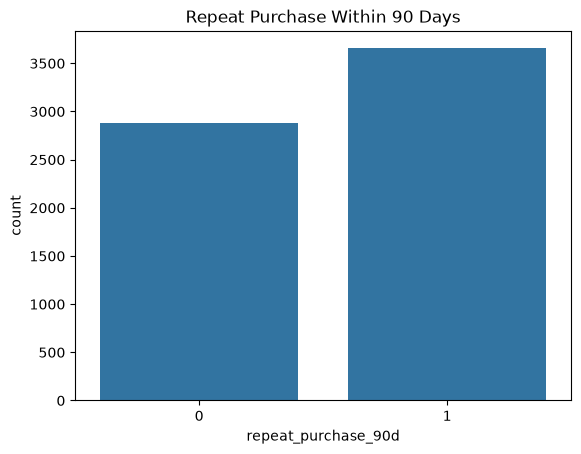

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=train_raw, x="repeat_purchase_90d")
plt.title("Repeat Purchase Within 90 Days")
plt.show()

In [17]:
pd.crosstab(
    train_raw["repeat_purchase_90d"],
    train_raw["spend_next_90d"].isna(),
    margins=True
)

spend_next_90d,False,True,All
repeat_purchase_90d,,,
0,0,2880,2880
1,3425,229,3654
All,3425,3109,6534


In [19]:
cols = [
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days"
]

train_raw.groupby("prior_purchase_count")[cols].apply(
    lambda x: x.isna().mean()
).head(10)

,prior_mean_purchase_value,prior_std_purchase_value,prior_mean_gap_days,prior_std_gap_days
prior_purchase_count,,,,
0.0,1.000000,1.0,1.000000,1.0
1.0,0.044944,1.0,1.000000,1.0
2.0,0.030137,0.0,0.057534,1.0
3.0,0.043887,0.0,0.053292,0.0
4.0,0.040741,0.0,0.025926,0.0
5.0,0.028226,0.0,0.032258,0.0
6.0,0.027027,0.0,0.031532,0.0
7.0,0.029557,0.0,0.054187,0.0
8.0,0.041667,0.0,0.036458,0.0


In [20]:
missing_rows = train_raw[train_raw["Total a Pagar"].isna()]

missing_rows.isna().sum().sort_values(ascending=False)

Total a Pagar                     65
Total Bruto                       65
Total Liquido                     65
Total Imp_                        65
Total Portes                      65
Total Desc_ Global                65
Total Desc_ Linha                 65
Custo                             65
N_ Detalhes                       65
invoice_count_current_purchase    65
spend_next_90d                    65
days_since_previous_purchase      65
prior_purchase_count              65
customer_tenure_days              65
prior_total_spend                 65
prior_mean_purchase_value         65
prior_mean_gap_days               65
prior_std_purchase_value          65
prior_min_purchase_value          65
prior_max_purchase_value          65
purchase_count_30d                65
prior_std_gap_days                65
spend_30d                         65
purchase_count_90d                65
document_series                   65
spend_90d                         65
purchase_count_180d               65
s

In [21]:
import numpy as np

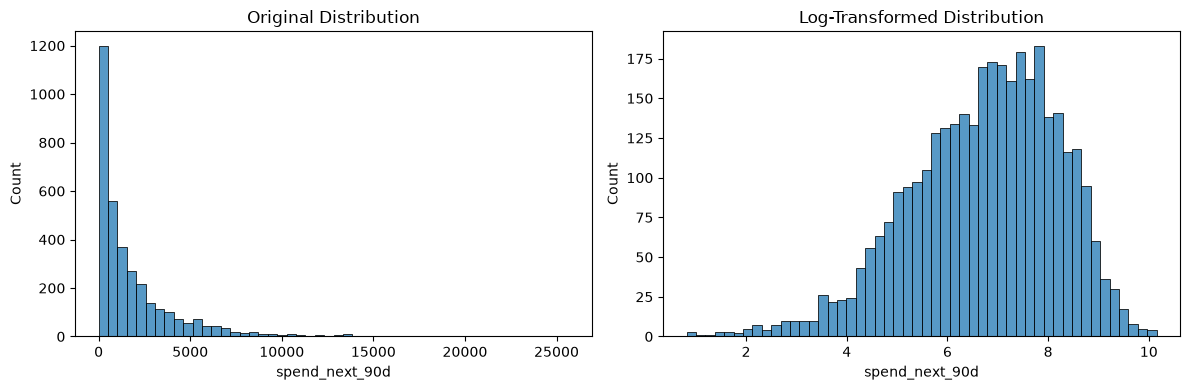

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(train_raw["spend_next_90d"].dropna(), bins=50, ax=axes[0])
axes[0].set_title("Original Distribution")

sns.histplot(
    np.log1p(train_raw["spend_next_90d"].dropna()),
    bins=50,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed Distribution")

plt.tight_layout()

In [23]:
features = [
    "customer_tenure_days",
    "prior_purchase_count",
    "prior_total_spend",
    "days_since_previous_purchase",
    "purchase_count_90d",
    "spend_90d"
]

train_raw.groupby("repeat_purchase_90d")[features].median().T

repeat_purchase_90d,0,1
customer_tenure_days,781.000,1032.00
prior_purchase_count,6.000,17.00
prior_total_spend,3246.525,12098.99
days_since_previous_purchase,105.000,37.00
purchase_count_90d,0.000,1.00
spend_90d,0.000,746.19


In [24]:
numeric_df = train_raw.select_dtypes(include="number")

corr = numeric_df.corr()["spend_next_90d"].sort_values(
    ascending=False
)

print(corr)

spend_next_90d                    1.000000
spend_180d                        0.582027
prior_total_spend                 0.550631
spend_90d                         0.519894
prior_std_purchase_value          0.392127
prior_purchase_count              0.292406
purchase_count_365d               0.287524
spend_30d                         0.280951
purchase_count_180d               0.257102
purchase_count_90d                0.253500
prior_max_purchase_value          0.245890
purchase_count_30d                0.206593
Total Desc_ Linha                 0.201987
Total Bruto                       0.187120
Total a Pagar                     0.169237
Total Liquido                     0.167918
Total Imp_                        0.161193
Total Portes                      0.144586
Custo                             0.117443
customer_tenure_days              0.092881
invoice_count_current_purchase    0.083158
N_ Detalhes                       0.072547
spend_365d                        0.005942
random_nois

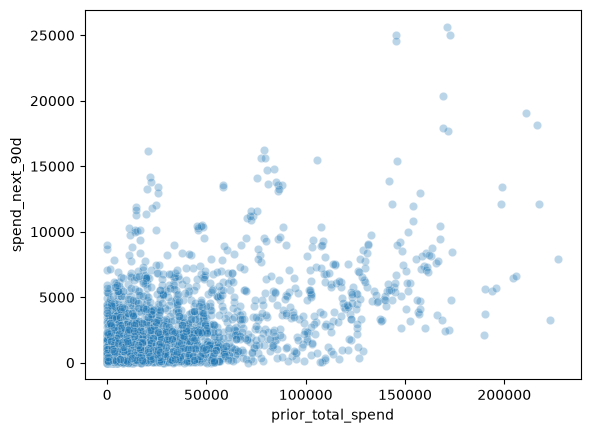

In [25]:
sns.scatterplot(
    data=train_raw,
    x="prior_total_spend",
    y="spend_next_90d",
    alpha=0.3
)
plt.show()

In [26]:
categorical_cols = train_raw.select_dtypes(include=["object", "str"]).columns  

train_raw[categorical_cols].nunique().sort_values(ascending=False)

purchase_date       1492
transport_method      80
payment_type           9
salesperson            9
commercial_zone        5
document_series        3
warehouse              2
dtype: int64

In [27]:
train_raw.groupby("commercial_zone")["repeat_purchase_90d"].agg(
    ["count", "mean"]
).sort_values("mean", ascending=False)

,count,mean
commercial_zone,,
Decorative Dashboard Zone 4,6260,0.565335
Decorative Dashboard Zone 2,151,0.410596
Decorative Dashboard Zone 3,56,0.357143
Decorative Dashboard Zone 6,1,0.000000
Decorative Dashboard Zone 7,1,0.000000


In [28]:
print("Duplicate rows:", train_raw.duplicated().sum())
print("Duplicate IDs:", train_raw["ID"].duplicated().sum())
print("Unique customers:", train_raw["customer_id"].nunique())

Duplicate rows: 0
Duplicate IDs: 0
Unique customers: 610


2015-07-11 00:00:00
2025-02-15 00:00:00


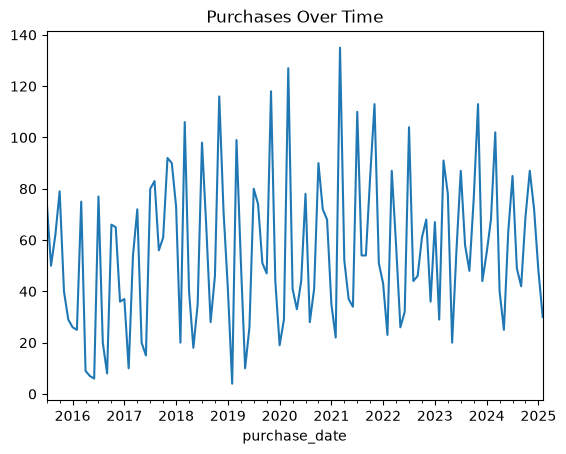

In [47]:
train_raw["purchase_date"] = pd.to_datetime(
    train_raw["purchase_date"], errors="coerce"
)

print(train_raw["purchase_date"].min())
print(train_raw["purchase_date"].max())

train_raw.set_index("purchase_date").resample("ME").size().plot()
plt.title("Purchases Over Time")
plt.show()

In [48]:
missing_spend = train_raw[
    (train_raw["repeat_purchase_90d"] == 1) &
    (train_raw["spend_next_90d"].isna())
]

missing_spend.isna().sum().sort_values(ascending=False)

spend_next_90d                    229
prior_std_gap_days                 95
prior_mean_gap_days                85
prior_std_purchase_value           79
prior_mean_purchase_value          68
days_since_previous_purchase       67
prior_max_purchase_value           63
prior_min_purchase_value           63
spend_365d                         48
salesperson                        41
transport_method                   40
warehouse                          39
payment_type                       38
Total Liquido                      33
Total Bruto                        33
Total a Pagar                      33
Custo                              33
Total Desc_ Linha                  33
Total Desc_ Global                 33
Total Portes                       33
Total Imp_                         33
N_ Detalhes                        33
customer_tenure_days               33
prior_total_spend                  33
document_series                    33
spend_30d                          33
invoice_coun

In [49]:
returning = train_raw[train_raw["repeat_purchase_90d"] == 1].copy()

returning.groupby(
    returning["spend_next_90d"].isna()
)[[
    "prior_purchase_count",
    "prior_total_spend",
    "customer_tenure_days",
    "Total a Pagar"
]].median()

,prior_purchase_count,prior_total_spend,customer_tenure_days,Total a Pagar
spend_next_90d,,,,
False,17.0,12318.840,1040.0,519.95
True,8.5,6407.135,828.5,487.14


In [51]:
pd.crosstab(
    train_raw["Total a Pagar"].isna(),
    train_raw["repeat_purchase_90d"],
    margins=True
)

repeat_purchase_90d,0,1,All
Total a Pagar,,,
False,2848,3621,6469
True,32,33,65
All,2880,3654,6534


In [52]:
missing_rows = train_raw[train_raw["Total a Pagar"].isna()]

print("Unique customers:", missing_rows["customer_id"].nunique())

print(missing_rows["customer_id"].value_counts().head(10))

Unique customers: 53
customer_id
755628    5
258332    3
427118    2
334782    2
239651    2
928824    2
475032    2
264090    2
508217    1
670446    1
Name: count, dtype: int64


In [53]:
affected_customers = missing_rows["customer_id"].unique()

train_raw[
    train_raw["customer_id"].isin(affected_customers)
].groupby("customer_id")["Total a Pagar"].agg(
    total="size",
    missing=lambda x: x.isna().sum(),
    complete=lambda x: x.notna().sum()
)

,total,missing,complete
customer_id,,,
103940,277,1,276
122356,35,1,34
128695,15,1,14
131189,22,1,21
133497,1,1,0
146476,24,1,23
151492,89,1,88
175924,29,1,28
185502,13,1,12


In [54]:
customer = train_raw[train_raw["customer_id"] == 103940]

incomplete = customer[customer["Total a Pagar"].isna()]

incomplete.T

,3214
Total a Pagar,NaN
Total Bruto,NaN
Total Liquido,NaN
Total Imp_,NaN
Total Portes,NaN
Total Desc_ Global,NaN
Total Desc_ Linha,NaN
Custo,NaN
N_ Detalhes,NaN
invoice_count_current_purchase,NaN


In [56]:
complete = customer[customer["Total a Pagar"].notna()]

pd.concat([
    incomplete.head(1).T.rename(columns={incomplete.index[0]: "Incomplete"}),
    complete.head(1).T.rename(columns={complete.index[0]: "Complete"})
], axis=1)

,Incomplete,Complete
Total a Pagar,NaN,10.33
Total Bruto,NaN,12.0
Total Liquido,NaN,8.4
Total Imp_,NaN,1.93
Total Portes,NaN,0.0
Total Desc_ Global,NaN,0.0
Total Desc_ Linha,NaN,3.6
Custo,NaN,6.097485
N_ Detalhes,NaN,1.0
invoice_count_current_purchase,NaN,1.0


In [57]:
cols = [
    "payment_type",
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series"
]

for col in cols:
    n_unique = train_raw.groupby("customer_id")[col].nunique()

    print(f"\n{col}")
    print(f"Customers with only 1 unique value: {(n_unique == 1).sum()}")
    print(f"Customers with multiple values: {(n_unique > 1).sum()}")
    print(f"Customers with no known values: {(n_unique == 0).sum()}")


payment_type
Customers with only 1 unique value: 521
Customers with multiple values: 80
Customers with no known values: 9

salesperson
Customers with only 1 unique value: 495
Customers with multiple values: 101
Customers with no known values: 14

commercial_zone
Customers with only 1 unique value: 603
Customers with multiple values: 4
Customers with no known values: 3

transport_method
Customers with only 1 unique value: 314
Customers with multiple values: 288
Customers with no known values: 8

warehouse
Customers with only 1 unique value: 592
Customers with multiple values: 13
Customers with no known values: 5

document_series
Customers with only 1 unique value: 307
Customers with multiple values: 300
Customers with no known values: 3


In [58]:
cols = [
    "payment_type",
    "salesperson",
    "commercial_zone",
    "transport_method",
    "warehouse",
    "document_series"
]

for col in cols:
    grouped = train_raw.groupby("customer_id")[col]

    n_known = grouped.count()
    n_unique = grouped.nunique()

    eligible = n_known >= 5

    stability = (
        (n_unique[eligible] == 1).mean() * 100
    )

    print(
        f"{col}: {stability:.2f}% stable "
        f"among {eligible.sum()} customers "
        f"with at least 5 known observations"
    )

payment_type: 75.93% stable among 270 customers with at least 5 known observations
salesperson: 71.16% stable among 267 customers with at least 5 known observations
commercial_zone: 98.89% stable among 271 customers with at least 5 known observations
transport_method: 19.26% stable among 270 customers with at least 5 known observations
warehouse: 97.01% stable among 268 customers with at least 5 known observations
document_series: 18.08% stable among 271 customers with at least 5 known observations


In [59]:
for col in cols:
    dominance = train_raw.groupby("customer_id")[col].apply(
        lambda x: x.value_counts(normalize=True).iloc[0]
        if x.notna().sum() >= 5 else float("nan")
    )

    print(f"{col}: {dominance.mean():.2%}")

payment_type: 96.05%
salesperson: 90.92%
commercial_zone: 99.85%
transport_method: 74.95%
warehouse: 99.13%
document_series: 66.67%


### EDA Finding: Customer-Based Group Aggregation for Missing Value Imputation

During the missing-value analysis, we identified 65 observations with almost all features missing. However, most of these customers have other purchase records containing valid information.

**Idea:** Instead of immediately removing these observations or using global imputation methods (mean, median, mode, KNN), we could explore **customer-based imputation using group aggregation**.

By grouping observations by `customer_id`, we can identify each customer's most frequent categorical values (mode) and potentially use them to fill missing values.

To investigate whether this approach is reasonable, we calculated the average dominance of each customer's most frequent category, considering only customers with at least 5 known observations.

| Feature | Average Dominance |
|---|---:|
| commercial_zone | 99.85% |
| warehouse | 99.13% |
| payment_type | 96.05% |
| salesperson | 90.92% |
| transport_method | 74.95% |
| document_series | 66.67% |

**Interpretation:** Variables such as `commercial_zone`, `warehouse`, `payment_type`, and `salesperson` show strong within-customer consistency, suggesting that customer-specific mode imputation could be more appropriate than global imputation for these features.

**Potential approach:**
1. Group observations by `customer_id`.
2. Calculate the mode of each categorical variable for each customer.
3. Use the customer-specific mode to impute missing values where sufficient historical information exists.
4. Fall back to another imputation strategy when customer history is unavailable.
5. Compare this approach against simpler imputation methods using validation.

**Important limitation:** The project requires predictions to use only information available at the time of purchase. Group aggregation must therefore avoid using future transactions or validation/test information. This is particularly challenging for the 65 observations with missing `purchase_date`.

**Next step:** During preprocessing, test whether customer-based imputation improves missing-value recovery and classification performance compared with standard imputation methods. For now, this remains a hypothesis supported by exploratory analysis, not a finalized preprocessing decision.

In [63]:
bins = [-1, 0, 1, 5, 10, 20, 50, float("inf")]

train_raw.assign(
    purchase_group=pd.cut(
        train_raw["prior_purchase_count"],
        bins=bins
    )
).groupby("purchase_group", observed=True)[
    "repeat_purchase_90d"
].agg(["count", "mean"])

,count,mean
purchase_group,,
"(-1.0, 0.0]",603,0.333333
"(0.0, 1.0]",445,0.373034
"(1.0, 5.0]",1202,0.423461
"(5.0, 10.0]",959,0.482795
"(10.0, 20.0]",1185,0.562025
"(20.0, 50.0]",1367,0.699342
"(50.0, inf]",708,0.932203


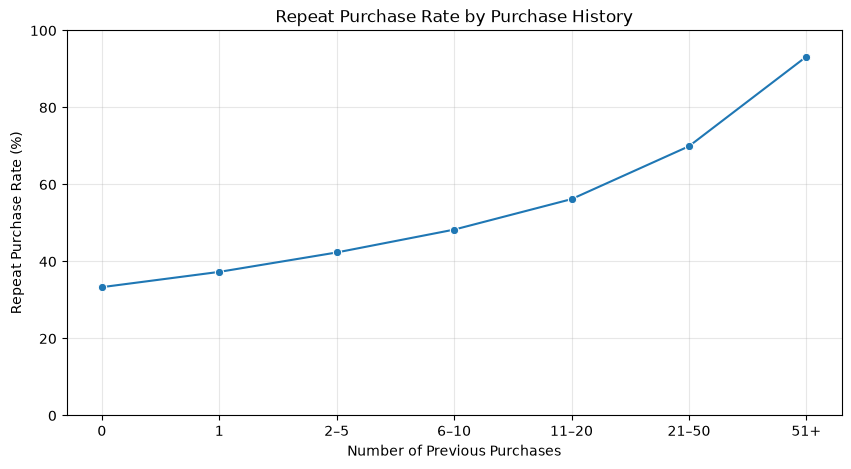

In [64]:
bins = [-1, 0, 1, 5, 10, 20, 50, float("inf")]

purchase_analysis = (
    train_raw.assign(
        purchase_group=pd.cut(
            train_raw["prior_purchase_count"],
            bins=bins
        )
    )
    .groupby("purchase_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=range(len(purchase_analysis)),
    y=purchase_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(purchase_analysis)),
    ["0", "1", "2–5", "6–10", "11–20", "21–50", "51+"]
)

plt.xlabel("Number of Previous Purchases")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Purchase History")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

### Relationship Between Purchase History and Repeat Purchase Probability

To investigate whether previous purchasing activity is associated with customer retention, observations were grouped according to `prior_purchase_count`. For each group, the proportion of customers who made another purchase within 90 days was calculated using the mean of the binary target `repeat_purchase_90d`.

The results reveal a clear positive, monotonic relationship between purchase history and repeat purchase probability. The repeat purchase rate increases from **33.3% for observations with no previous purchases** to **93.2% for observations with more than 50 previous purchases**.

This suggests that customers with a longer purchasing history are considerably more likely to return within 90 days, making `prior_purchase_count` a potentially important predictor for the classification task.

However, this relationship is associative rather than causal. Further analysis is needed to determine whether the observed pattern is partly explained by other variables, particularly purchase recency (`days_since_previous_purchase`).

Additionally, because purchase-count intervals have unequal widths, the line chart should be interpreted as a comparison between ordered groups rather than evidence of a specific mathematical relationship.

In [65]:
bins = [-1, 7, 30, 60, 90, 180, 365, float("inf")]

labels = [
    "0–7 days",
    "8–30 days",
    "31–60 days",
    "61–90 days",
    "91–180 days",
    "181–365 days",
    "365+ days"
]

recency_analysis = (
    train_raw.assign(
        recency_group=pd.cut(
            train_raw["days_since_previous_purchase"],
            bins=bins,
            labels=labels
        )
    )
    .groupby("recency_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

recency_analysis

,count,mean
recency_group,,
0–7 days,702,0.794872
8–30 days,1355,0.690775
31–60 days,832,0.689904
61–90 days,564,0.661348
91–180 days,1430,0.416783
181–365 days,547,0.369287
365+ days,227,0.290749


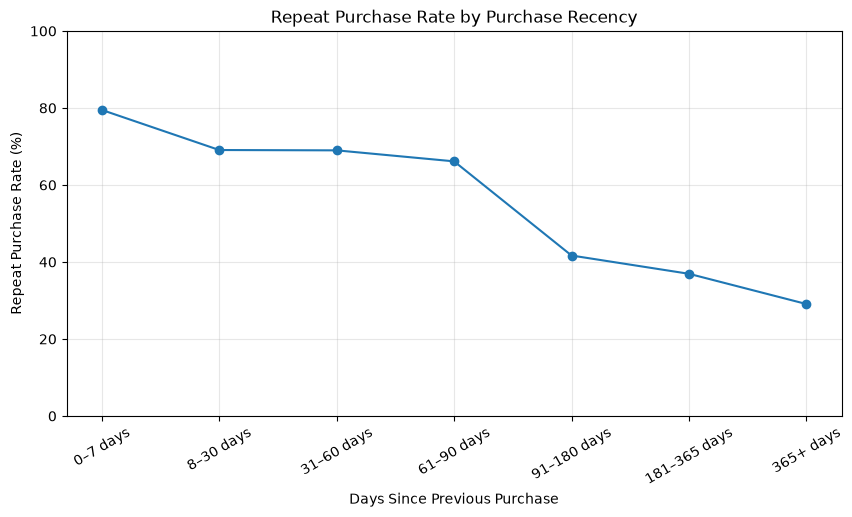

In [66]:
plt.figure(figsize=(10, 5))

plt.plot(
    recency_analysis.index.astype(str),
    recency_analysis["mean"] * 100,
    marker="o"
)

plt.xlabel("Days Since Previous Purchase")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Purchase Recency")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.xticks(rotation=30)
plt.show()

In [67]:
monetary_analysis = (
    train_raw.assign(
        monetary_group=pd.qcut(
            train_raw["prior_total_spend"],
            q=5,
            duplicates="drop"
        )
    )
    .groupby("monetary_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

monetary_analysis

,count,mean
monetary_group,,
"(-0.001, 956.866]",1294,0.349304
"(956.866, 4149.69]",1294,0.444359
"(4149.69, 10611.24]",1293,0.534416
"(10611.24, 28047.774]",1294,0.656105
"(28047.774, 247865.1]",1294,0.814529


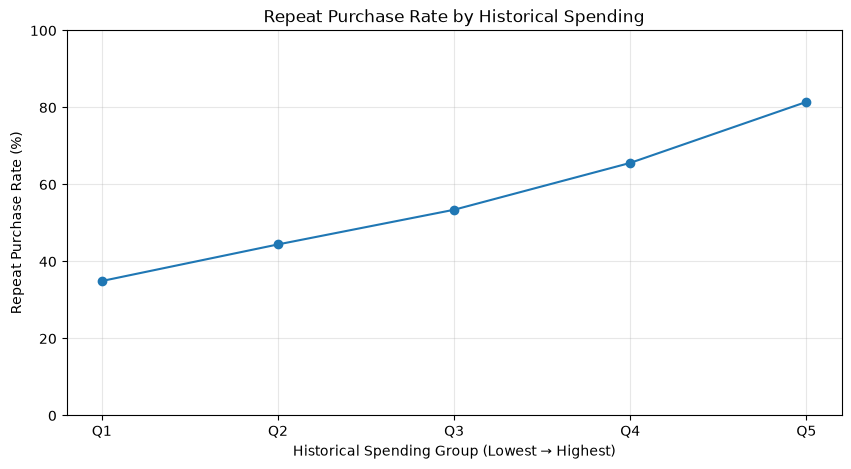

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(monetary_analysis)),
    monetary_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(monetary_analysis)),
    [f"Q{i+1}" for i in range(len(monetary_analysis))]
)

plt.xlabel("Historical Spending Group (Lowest → Highest)")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Historical Spending")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

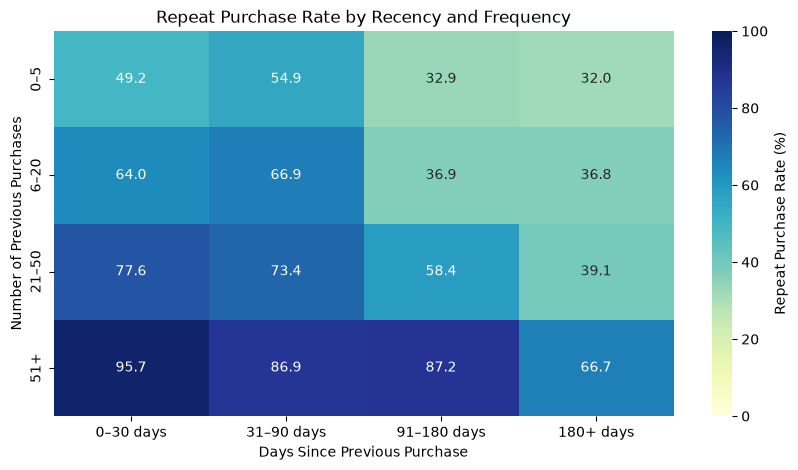

recency_group,0–30 days,31–90 days,91–180 days,180+ days
frequency_group,,,,
0–5,390,335,438,403
6–20,616,517,645,299
21–50,539,414,308,69
51+,512,130,39,3


In [69]:
rf_data = train_raw[
    ["prior_purchase_count", "days_since_previous_purchase", "repeat_purchase_90d"]
].dropna().copy()

rf_data["frequency_group"] = pd.cut(
    rf_data["prior_purchase_count"],
    bins=[-1, 5, 20, 50, float("inf")],
    labels=["0–5", "6–20", "21–50", "51+"]
)

rf_data["recency_group"] = pd.cut(
    rf_data["days_since_previous_purchase"],
    bins=[-1, 30, 90, 180, float("inf")],
    labels=["0–30 days", "31–90 days", "91–180 days", "180+ days"]
)

rf_rates = rf_data.pivot_table(
    index="frequency_group",
    columns="recency_group",
    values="repeat_purchase_90d",
    aggfunc="mean",
    observed=True
)

rf_counts = rf_data.pivot_table(
    index="frequency_group",
    columns="recency_group",
    values="repeat_purchase_90d",
    aggfunc="count",
    observed=True
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    rf_rates * 100,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Repeat Purchase Rate (%)"}
)

plt.title("Repeat Purchase Rate by Recency and Frequency")
plt.xlabel("Days Since Previous Purchase")
plt.ylabel("Number of Previous Purchases")
plt.show()

display(rf_counts)

### Recency × Frequency Interaction Analysis

A heatmap was constructed to investigate the relationship between purchase recency, historical purchase frequency, and the probability of purchasing again within 90 days.

The results indicate that both recency and frequency are associated with repeat purchase behavior. Among customers who purchased within the previous 30 days, repeat purchase rates increase from 49.2% for those with 0–5 previous purchases to 95.7% for those with more than 50.

Similarly, among customers with 21–50 previous purchases, the repeat purchase rate decreases from 77.6% for those who purchased within the last 30 days to 39.1% for those inactive for more than 180 days.

These findings suggest that historical purchase frequency and recency provide complementary information about customer purchasing behavior.

However, some combinations contain very few observations, particularly customers with more than 50 previous purchases and more than 180 days of inactivity (n = 3). Estimates for these groups should be interpreted cautiously.

Overall, the analysis supports the potential predictive relevance of both `prior_purchase_count` and `days_since_previous_purchase` for the classification task.

In [70]:
train_raw[["prior_purchase_count", "prior_total_spend"]].corr(
    method="spearman"
)

,prior_purchase_count,prior_total_spend
prior_purchase_count,1.00000,0.90327
prior_total_spend,0.90327,1.00000


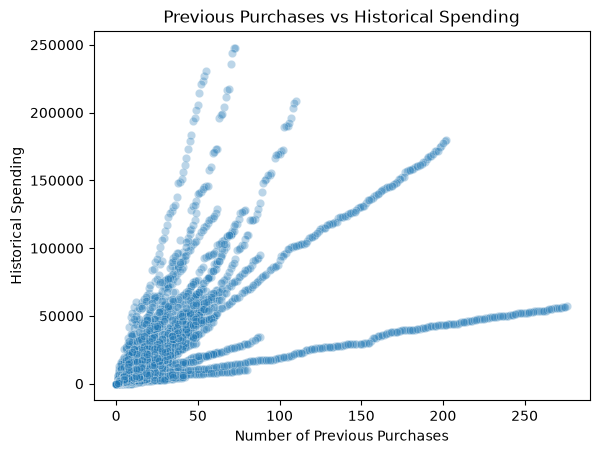

In [71]:
sns.scatterplot(
    data=train_raw,
    x="prior_purchase_count",
    y="prior_total_spend",
    alpha=0.3
)

plt.title("Previous Purchases vs Historical Spending")
plt.xlabel("Number of Previous Purchases")
plt.ylabel("Historical Spending")
plt.show()

In [72]:
avg_spend_data = train_raw[
    train_raw["prior_purchase_count"] > 0
].copy()

avg_spend_data["avg_purchase_value"] = (
    avg_spend_data["prior_total_spend"]
    / avg_spend_data["prior_purchase_count"]
)

avg_spend_data["spending_group"] = pd.qcut(
    avg_spend_data["avg_purchase_value"],
    q=5,
    duplicates="drop"
)

avg_spend_data.groupby("spending_group", observed=True)[
    "repeat_purchase_90d"
].agg(["count", "mean"])

,count,mean
spending_group,,
"(3.309, 288.072]",1174,0.579216
"(288.072, 579.913]",1173,0.461211
"(579.913, 847.464]",1173,0.566070
"(847.464, 1223.306]",1173,0.676044
"(1223.306, 6685.165]",1173,0.632566


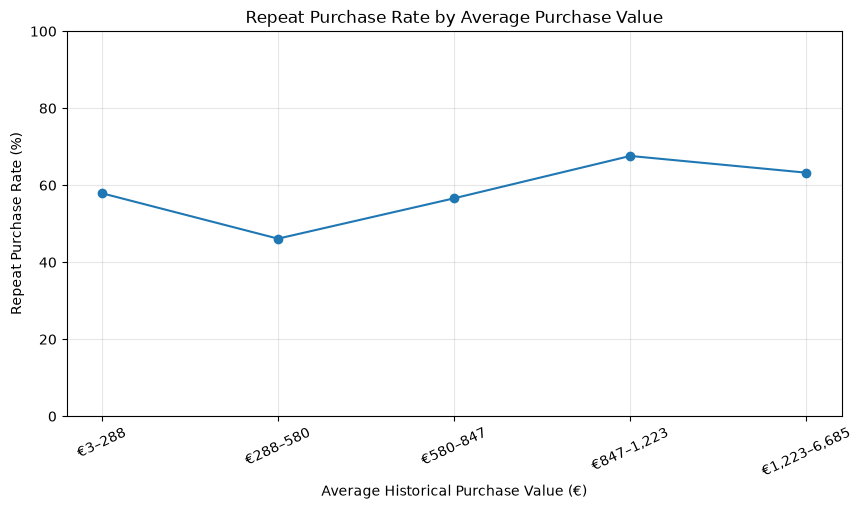

In [75]:
spending_analysis = avg_spend_data.groupby(
    "spending_group", observed=True
)["repeat_purchase_90d"].agg(["count", "mean"])

plt.figure(figsize=(10, 5))

plt.plot(
    range(len(spending_analysis)),
    spending_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(spending_analysis)),
    ["€3–288", "€288–580", "€580–847", "€847–1,223", "€1,223–6,685"],
    rotation=25
)
plt.xlabel("Average Historical Purchase Value (€)")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Average Purchase Value")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

Although total historical spending exhibits a strong positive association with repeat purchase probability, average spending per previous purchase shows a less consistent, non-monotonic relationship. Combined with the strong correlation between purchase frequency and total spending (Spearman ρ = 0.903), this suggests that the association between total spending and customer retention may be partly explained by purchase frequency. Further analysis would be required to establish whether average purchase value provides additional predictive information.

In [76]:
transaction_analysis = (
    train_raw.assign(
        transaction_group=pd.qcut(
            train_raw["Total a Pagar"],
            q=5,
            duplicates="drop"
        )
    )
    .groupby("transaction_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

transaction_analysis

,count,mean
transaction_group,,
"(0.929, 146.228]",1294,0.568006
"(146.228, 340.74]",1294,0.509274
"(340.74, 652.452]",1293,0.522815
"(652.452, 1339.002]",1294,0.559505
"(1339.002, 22297.21]",1294,0.639104


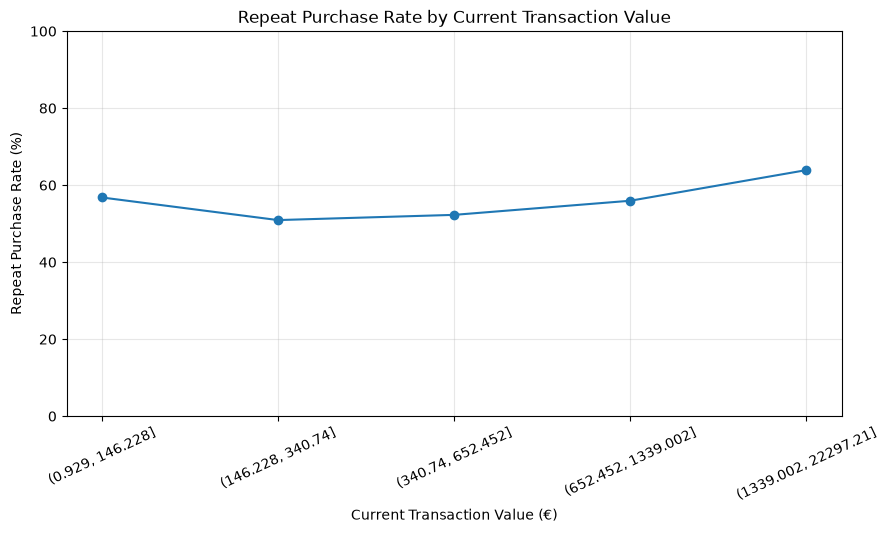

In [77]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(transaction_analysis)),
    transaction_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(transaction_analysis)),
    [str(group) for group in transaction_analysis.index],
    rotation=25
)

plt.xlabel("Current Transaction Value (€)")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Current Transaction Value")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

### Current Transaction Value and Repeat Purchase Probability

To investigate whether the value of the current transaction is associated with future purchasing behavior, `Total a Pagar` was divided into five quantile-based groups.

The results show a relatively weak, non-monotonic relationship between current transaction value and the probability of purchasing again within 90 days. Repeat purchase rates range from approximately 50.9% to 63.9%, with the highest-value transactions exhibiting the greatest repeat purchase rate.

Compared with historical purchase frequency and total spending, current transaction value shows a less pronounced association with repeat purchasing.

This suggests that historical customer behavior may provide stronger individual signals for predicting repeat purchases than the monetary value of a single transaction. However, the additional predictive contribution of current transaction value remains to be evaluated.

In [80]:
payment_analysis = (
    train_raw.groupby("payment_type")["repeat_purchase_90d"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

payment_analysis

,count,mean
payment_type,,
Maybe Tomorrow Payment 9,502,0.950199
Maybe Tomorrow Payment 11,8,0.625000
Maybe Tomorrow Payment 12,991,0.542886
Maybe Tomorrow Payment 7,4565,0.527273
Maybe Tomorrow Payment 2,21,0.523810
Maybe Tomorrow Payment 3,4,0.500000
Maybe Tomorrow Payment 4,9,0.444444
Maybe Tomorrow Payment 10,134,0.402985
Maybe Tomorrow Payment 8,40,0.325000


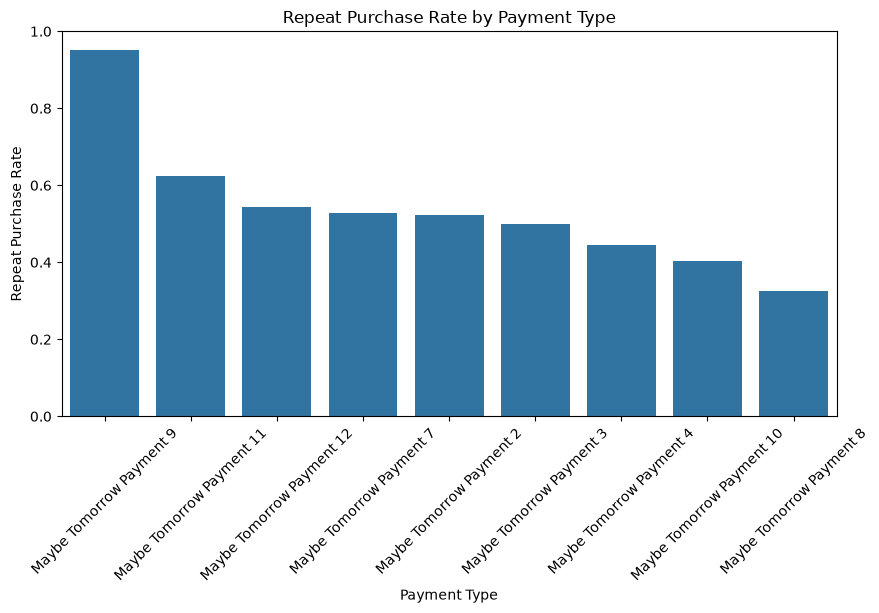

In [81]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=payment_analysis.reset_index(),
    x="payment_type",
    y="mean"
)

plt.title("Repeat Purchase Rate by Payment Type")
plt.xlabel("Payment Type")
plt.ylabel("Repeat Purchase Rate")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.show()

In [82]:
train_raw.groupby("payment_type").agg(
    observations=("customer_id", "size"),
    unique_customers=("customer_id", "nunique"),
    median_previous_purchases=("prior_purchase_count", "median"),
    median_recency=("days_since_previous_purchase", "median"),
    median_historical_spend=("prior_total_spend", "median"),
    repeat_rate=("repeat_purchase_90d", "mean")
).sort_values("repeat_rate", ascending=False)

,observations,unique_customers,median_previous_purchases,median_recency,median_historical_spend,repeat_rate
payment_type,,,,,,
Maybe Tomorrow Payment 9,502,10,109.5,8.0,39383.730,0.950199
Maybe Tomorrow Payment 11,8,2,3.5,77.0,7515.770,0.625000
Maybe Tomorrow Payment 12,991,218,5.0,45.5,1522.090,0.542886
Maybe Tomorrow Payment 7,4565,418,11.0,70.0,7083.670,0.527273
Maybe Tomorrow Payment 2,21,6,5.0,108.5,9278.130,0.523810
Maybe Tomorrow Payment 3,4,3,2.5,391.5,4146.550,0.500000
Maybe Tomorrow Payment 4,9,2,6.0,129.0,13053.940,0.444444
Maybe Tomorrow Payment 10,134,23,4.0,102.0,7422.095,0.402985
Maybe Tomorrow Payment 8,40,6,5.0,112.0,5089.180,0.325000


Payment type exhibits substantial differences in repeat purchase rates. However, the highest-performing category, Payment 9 (95.0%), contains 502 observations from only 10 customers, who also demonstrate considerably higher purchase frequency and recency. Therefore, the observed association may largely reflect customer characteristics rather than an independent effect of payment type.

In [83]:
categorical_cols = [
    "salesperson",
    "commercial_zone",
    "warehouse",
    "transport_method",
    "document_series"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")

    summary = (
        train_raw.groupby(col)["repeat_purchase_90d"]
        .agg(["count", "mean"])
        .sort_values("count", ascending=False)
    )

    display(summary.head(10))


--- salesperson ---


,count,mean
salesperson,,
VLOOKUP Master 1,4054,0.624322
VLOOKUP Master 4,1461,0.394251
VLOOKUP Master 9,384,0.546875
VLOOKUP Master 7,201,0.482587
VLOOKUP Master 2,123,0.601626
VLOOKUP Master 3,30,0.366667
VLOOKUP Master 6,12,0.000000
VLOOKUP Master 5,7,0.428571
VLOOKUP Master 8,3,1.000000



--- commercial_zone ---


,count,mean
commercial_zone,,
Decorative Dashboard Zone 4,6260,0.565335
Decorative Dashboard Zone 2,151,0.410596
Decorative Dashboard Zone 3,56,0.357143
Decorative Dashboard Zone 6,1,0.000000
Decorative Dashboard Zone 7,1,0.000000



--- warehouse ---


,count,mean
warehouse,,
Final Excel Warehouse 1,6253,0.556533
Final Excel Warehouse 3,21,0.809524



--- transport_method ---


,count,mean
transport_method,,
Maybe Tomorrow Delivery 72,1119,0.493298
Maybe Tomorrow Delivery 61,627,0.601276
Maybe Tomorrow Delivery 73,445,0.494382
Maybe Tomorrow Delivery 59,373,0.493298
Maybe Tomorrow Delivery 80,319,0.645768
Maybe Tomorrow Delivery 71,301,0.544850
Maybe Tomorrow Delivery 40,257,0.533074
Maybe Tomorrow Delivery 11,253,0.980237
Maybe Tomorrow Delivery 53,247,0.663968



--- document_series ---


,count,mean
document_series,,
Ctrl Z Series 2,2738,0.558072
Ctrl Z Series 3,1903,0.560694
Ctrl Z Series 1,1828,0.561269


In [84]:
for col in ["salesperson", "transport_method"]:
    summary = (
        train_raw.groupby(col)
        .agg(
            observations=("customer_id", "size"),
            unique_customers=("customer_id", "nunique"),
            median_previous_purchases=("prior_purchase_count", "median"),
            median_recency=("days_since_previous_purchase", "median"),
            repeat_rate=("repeat_purchase_90d", "mean")
        )
        .sort_values("observations", ascending=False)
    )

    print(f"\n--- {col} ---")
    display(summary.head(15))


--- salesperson ---


,observations,unique_customers,median_previous_purchases,median_recency,repeat_rate
salesperson,,,,,
VLOOKUP Master 1,4054,330,14.0,46.0,0.624322
VLOOKUP Master 4,1461,199,8.0,103.0,0.394251
VLOOKUP Master 9,384,79,9.0,63.0,0.546875
VLOOKUP Master 7,201,48,3.0,55.0,0.482587
VLOOKUP Master 2,123,40,1.0,26.0,0.601626
VLOOKUP Master 3,30,20,0.0,44.5,0.366667
VLOOKUP Master 6,12,12,0.0,1253.5,0.000000
VLOOKUP Master 5,7,2,2.0,35.0,0.428571
VLOOKUP Master 8,3,2,1.0,25.5,1.000000



--- transport_method ---


,observations,unique_customers,median_previous_purchases,median_recency,repeat_rate
transport_method,,,,,
Maybe Tomorrow Delivery 72,1119,137,10.0,84.0,0.493298
Maybe Tomorrow Delivery 61,627,127,12.0,45.0,0.601276
Maybe Tomorrow Delivery 73,445,39,15.0,84.0,0.494382
Maybe Tomorrow Delivery 59,373,45,8.0,87.5,0.493298
Maybe Tomorrow Delivery 80,319,82,10.0,29.0,0.645768
Maybe Tomorrow Delivery 71,301,36,18.0,77.0,0.544850
Maybe Tomorrow Delivery 40,257,37,8.0,70.0,0.533074
Maybe Tomorrow Delivery 11,253,2,127.0,5.0,0.980237
Maybe Tomorrow Delivery 53,247,102,12.0,27.0,0.663968


In [85]:
discount_cols = [
    "Total Desc_ Global",
    "Total Desc_ Linha"
]

train_raw[discount_cols].describe()

,Total Desc_ Global,Total Desc_ Linha
count,6469.000000,6469.000000
mean,0.349907,112.466414
std,5.116564,289.986307
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,13.130000
75%,0.000000,92.280000
max,218.490000,4103.440000


In [86]:
for col in discount_cols:
    print(f"\n{col}")
    print("Zero:", (train_raw[col] == 0).sum())
    print("Positive:", (train_raw[col] > 0).sum())
    print("Negative:", (train_raw[col] < 0).sum())
    print("Missing:", train_raw[col].isna().sum())


Total Desc_ Global
Zero: 6359
Positive: 110
Negative: 0
Missing: 65

Total Desc_ Linha
Zero: 2441
Positive: 4028
Negative: 0
Missing: 65


In [87]:
discount_analysis = (
    train_raw.assign(
        has_line_discount=train_raw["Total Desc_ Linha"] > 0
    )
    .dropna(subset=["Total Desc_ Linha"])
    .groupby("has_line_discount")["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

discount_analysis

,count,mean
has_line_discount,,
False,2441,0.450635
True,4028,0.625869


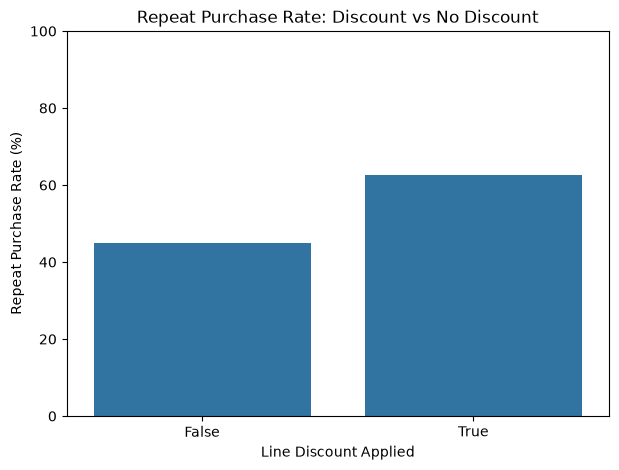

In [88]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=discount_analysis.index.astype(str),
    y=discount_analysis["mean"] * 100
)

plt.xlabel("Line Discount Applied")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate: Discount vs No Discount")
plt.ylim(0, 100)
plt.show()

Hypothesis 1: Discounts are associated with customers returning more frequently. 

Hypothesis 2: Regular customers are more likely to receive discounts in the first place.

In [89]:
discount_history = (
    train_raw.dropna(subset=["Total Desc_ Linha"])
    .assign(
        has_line_discount=lambda df: df["Total Desc_ Linha"] > 0
    )
    .groupby("has_line_discount")
    .agg(
        observations=("customer_id", "size"),
        unique_customers=("customer_id", "nunique"),
        median_previous_purchases=("prior_purchase_count", "median"),
        median_recency=("days_since_previous_purchase", "median"),
        median_historical_spend=("prior_total_spend", "median"),
        repeat_rate=("repeat_purchase_90d", "mean")
    )
)

discount_history

,observations,unique_customers,median_previous_purchases,median_recency,median_historical_spend,repeat_rate
has_line_discount,,,,,,
False,2441,411,7.0,63.0,4572.55,0.450635
True,4028,469,13.0,56.0,8599.08,0.625869


Our initial graph showed that discounted transactions have a 17.5-percentage-point higher repeat purchase rate.
But now we know those transactions are also associated with more established customers.
That means we cannot attribute the difference to discounts themselves.
We have two relationships happening simultaneously:
- More established customers tend to return more often.
- Discounted transactions tend to involve more established customers.
We haven't established whether discounts provide additional information after accounting for purchase history.
One more detail: the unique-customer counts overlap. A customer can have both discounted and non-discounted transactions, so 411 and 469 are not separate populations.

In [90]:
discounted = train_raw[
    train_raw["Total Desc_ Linha"] > 0
].copy()

discounted["discount_group"] = pd.qcut(
    discounted["Total Desc_ Linha"],
    q=5,
    duplicates="drop"
)

discount_size_analysis = (
    discounted.groupby("discount_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

discount_size_analysis

,count,mean
discount_group,,
"(0.059, 13.4]",807,0.573730
"(13.4, 40.806]",804,0.538557
"(40.806, 92.918]",806,0.619107
"(92.918, 236.88]",805,0.678261
"(236.88, 4103.44]",806,0.719603


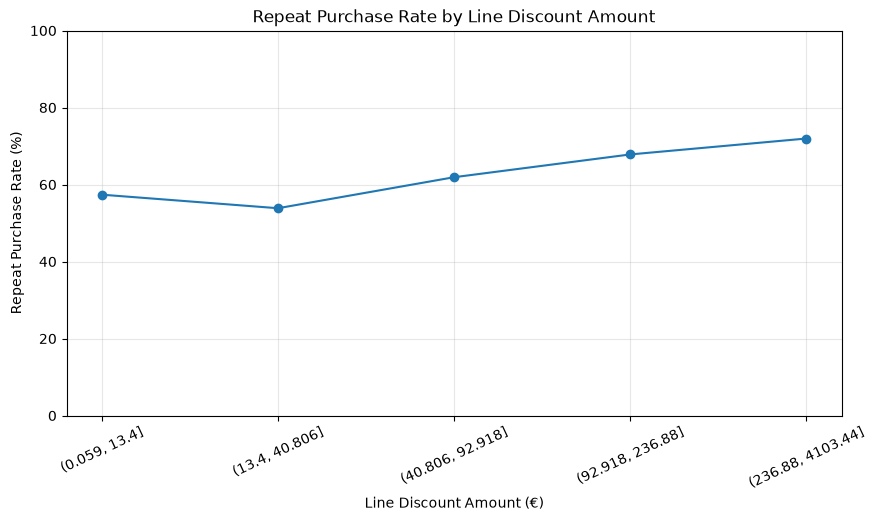

In [91]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(discount_size_analysis)),
    discount_size_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(discount_size_analysis)),
    [str(group) for group in discount_size_analysis.index],
    rotation=25
)

plt.xlabel("Line Discount Amount (€)")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Line Discount Amount")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

In [92]:
cols = [
    "Total Bruto",
    "Total Desc_ Linha",
    "Total Desc_ Global",
    "Total Liquido",
    "Total a Pagar"
]

display(train_raw[cols].dropna().head(10))

,Total Bruto,Total Desc_ Linha,Total Desc_ Global,Total Liquido,Total a Pagar
0,510.90,57.15,0.0,453.75,558.11
1,830.02,34.25,0.0,795.77,978.80
2,12.00,3.60,0.0,8.40,10.33
3,696.61,0.00,0.0,696.61,856.83
4,1488.85,174.95,0.0,1313.90,1616.10
5,568.24,47.28,0.0,520.96,640.78
6,105.55,5.12,0.0,100.43,122.83
7,1272.44,126.30,0.0,1146.14,1409.75
8,786.27,3.64,0.0,782.63,962.63
9,372.32,0.00,0.0,372.32,457.95


In [93]:
difference = (
    train_raw["Total Bruto"]
    - train_raw["Total Desc_ Linha"]
    - train_raw["Total Liquido"]
)

difference.dropna().abs().describe()

count    6469.000000
mean        0.349907
std         5.116564
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max       218.490000
dtype: float64

In [94]:
discount_data = train_raw[
    (train_raw["Total Bruto"] > 0)
    & (train_raw["Total Desc_ Linha"] > 0)
].copy()

discount_data["discount_pct"] = (
    discount_data["Total Desc_ Linha"]
    / discount_data["Total Bruto"] * 100
)

discount_data["discount_pct"].describe()

count    4028.000000
mean       17.674756
std        13.267872
min         0.008354
25%         5.869862
50%        16.000765
75%        25.006810
max        97.473684
Name: discount_pct, dtype: float64

In [95]:
difference = (
    train_raw["Total Bruto"]
    - train_raw["Total Desc_ Linha"]
    - train_raw["Total Desc_ Global"]
    - train_raw["Total Liquido"]
)

difference.dropna().abs().describe()

count    6.469000e+03
mean     2.500447e-14
std      1.014167e-13
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.637979e-12
dtype: float64

In [96]:
discount_data["discount_group"] = pd.qcut(
    discount_data["discount_pct"],
    q=5,
    duplicates="drop"
)

discount_pct_analysis = (
    discount_data.groupby("discount_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

discount_pct_analysis

,count,mean
discount_group,,
"(0.00735, 4.688]",806,0.514888
"(4.688, 11.882]",805,0.568944
"(11.882, 20.001]",806,0.621588
"(20.001, 28.883]",805,0.602484
"(28.883, 97.474]",806,0.821340


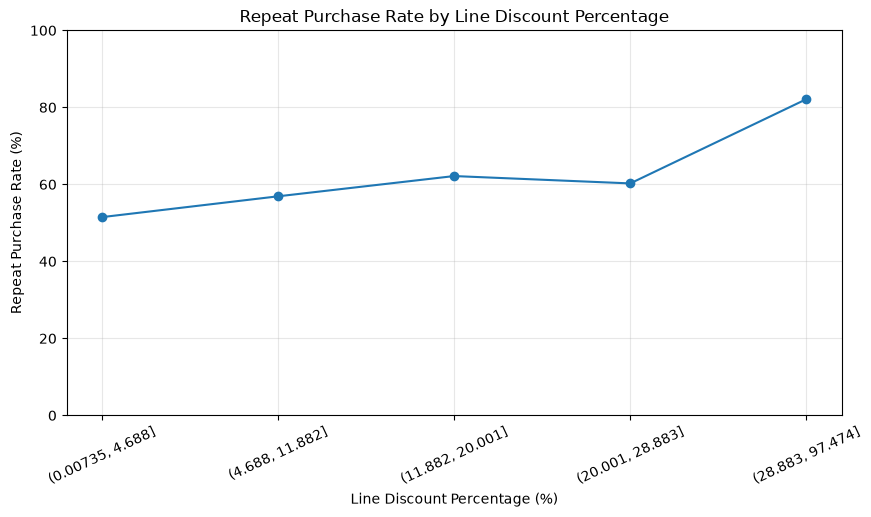

In [97]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(discount_pct_analysis)),
    discount_pct_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(discount_pct_analysis)),
    [str(group) for group in discount_pct_analysis.index],
    rotation=25
)

plt.xlabel("Line Discount Percentage (%)")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Line Discount Percentage")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

In [98]:
discount_profile = (
    discount_data.groupby("discount_group", observed=True)
    .agg(
        observations=("customer_id", "size"),
        unique_customers=("customer_id", "nunique"),
        median_previous_purchases=("prior_purchase_count", "median"),
        median_recency=("days_since_previous_purchase", "median"),
        median_transaction_value=("Total a Pagar", "median"),
        repeat_rate=("repeat_purchase_90d", "mean")
    )
)

discount_profile

,observations,unique_customers,median_previous_purchases,median_recency,median_transaction_value,repeat_rate
discount_group,,,,,,
"(0.00735, 4.688]",806,186,15.0,92.0,945.085,0.514888
"(4.688, 11.882]",805,257,10.0,69.0,547.530,0.568944
"(11.882, 20.001]",806,213,12.0,69.0,579.010,0.621588
"(20.001, 28.883]",805,205,9.0,63.0,526.280,0.602484
"(28.883, 97.474]",806,125,41.5,11.0,285.525,0.821340


### Discount Percentage and Customer Purchasing History

The relationship between line discount percentage and repeat purchasing was investigated by dividing discounted transactions into five quantile-based groups.

The highest discount group (28.9%–97.5%) exhibited a repeat purchase rate of **82.1%**, compared with **51.5%** for the lowest discount group (0%–4.7%).

However, further analysis revealed substantial differences in customer purchasing history. Transactions in the highest discount group had a median of 41.5 previous purchases and 11 days since the previous purchase, compared with 15 purchases and 92 days in the lowest discount group.

Additionally, the highest discount group contained fewer unique customers and had a lower median transaction value.

These findings suggest that the observed relationship between discount percentage and repeat purchasing may be partly explained by customer purchasing behavior. Therefore, the analysis does not establish that larger discounts cause higher customer retention.

In [100]:
train_raw["N_ Detalhes"].describe()

count    6469.000000
mean       21.524501
std        27.713419
min         1.000000
25%         4.000000
50%        11.000000
75%        29.000000
max       423.000000
Name: N_ Detalhes, dtype: float64

In [99]:
train_raw["N_ Detalhes"].value_counts().sort_index().head(30)

N_ Detalhes
1.0     720
2.0     480
3.0     372
4.0     302
5.0     254
6.0     236
7.0     236
8.0     208
9.0     183
10.0    163
11.0    132
12.0    129
13.0    141
14.0    128
15.0    116
16.0    107
17.0     99
18.0     83
19.0     80
20.0     97
21.0     94
22.0     62
23.0     80
24.0     69
25.0     81
26.0     63
27.0     54
28.0     71
29.0     64
30.0     53
Name: count, dtype: int64

In [102]:
bins = [0, 1, 5, 10, 20, 30, float("inf")]

labels = ["1", "2–5", "6–10", "11–20", "21–30", "31+"]

details_analysis = (
    train_raw.assign(
        details_group=pd.cut(
            train_raw["N_ Detalhes"],
            bins=bins,
            labels=labels
        )
    )
    .groupby("details_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

details_analysis

,count,mean
details_group,,
1,720,0.609722
2–5,1408,0.600142
6–10,1026,0.528265
11–20,1112,0.507194
21–30,691,0.531114
31+,1512,0.571429


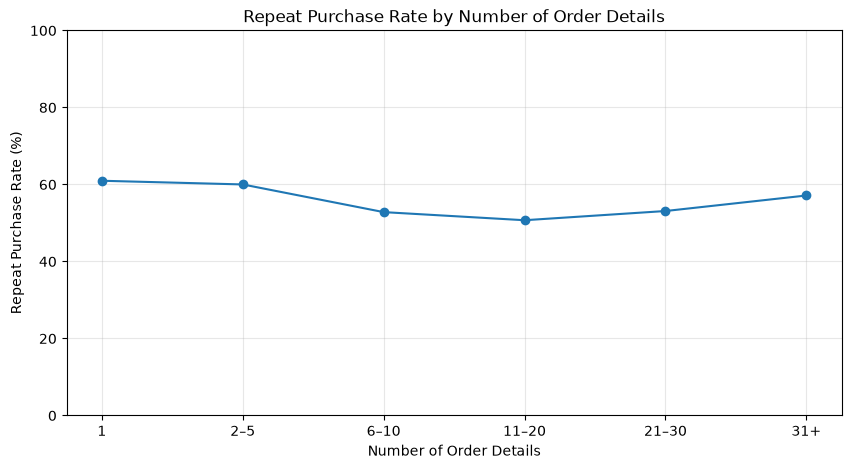

In [103]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(details_analysis)),
    details_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(details_analysis)),
    details_analysis.index
)

plt.xlabel("Number of Order Details")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Number of Order Details")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

In [104]:
temporal_data = train_raw.dropna(subset=["purchase_date"]).copy()

temporal_data["purchase_date"] = pd.to_datetime(
    temporal_data["purchase_date"]
)

temporal_data["year"] = temporal_data["purchase_date"].dt.year

yearly_analysis = (
    temporal_data.groupby("year")["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

yearly_analysis

,count,mean
year,,
2015,335,0.534328
2016,420,0.514286
2017,670,0.632836
2018,716,0.537709
2019,646,0.521672
2020,670,0.594030
2021,782,0.548593
2022,628,0.480892
2023,767,0.581486


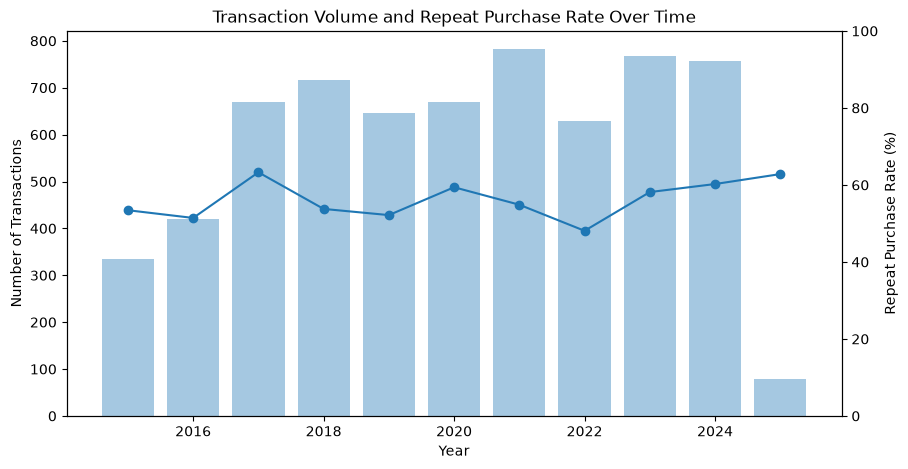

In [105]:
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(yearly_analysis.index, yearly_analysis["count"], alpha=0.4)
ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Transactions")

ax2 = ax1.twinx()
ax2.plot(
    yearly_analysis.index,
    yearly_analysis["mean"] * 100,
    marker="o"
)
ax2.set_ylabel("Repeat Purchase Rate (%)")
ax2.set_ylim(0, 100)

plt.title("Transaction Volume and Repeat Purchase Rate Over Time")
plt.show()

In [106]:
temporal_data["month"] = temporal_data["purchase_date"].dt.month

monthly_analysis = (
    temporal_data.groupby("month")["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

monthly_analysis

,count,mean
month,,
1,444,0.689189
2,260,0.619231
3,876,0.438356
4,442,0.511312
5,196,0.724490
6,311,0.604502
7,874,0.488558
8,525,0.609524
9,436,0.692661


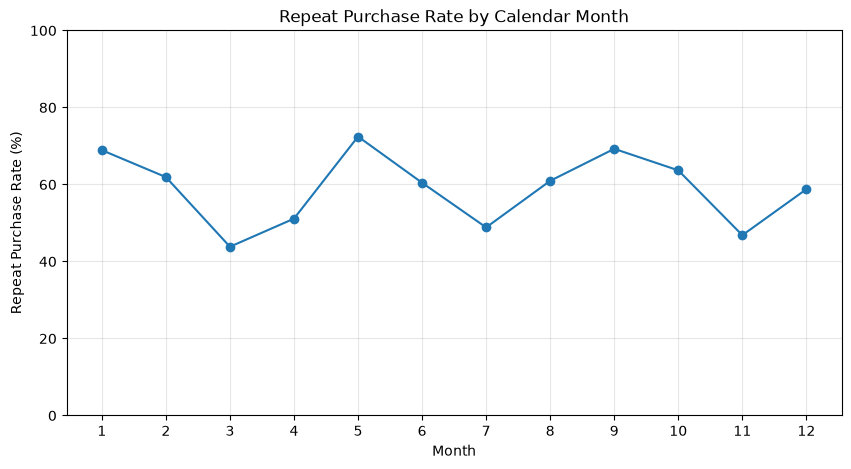

In [107]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_analysis.index,
    monthly_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Calendar Month")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

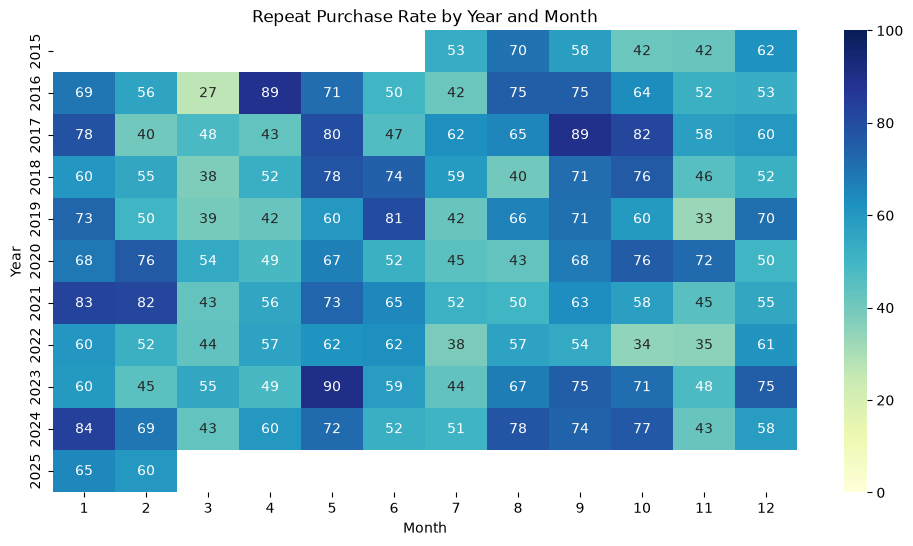

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2015,NaN,NaN,NaN,NaN,NaN,NaN,75.0,50.0,62.0,79.0,40.0,29.0
2016,26.0,25.0,75.0,9.0,7.0,6.0,77.0,20.0,8.0,66.0,65.0,36.0
2017,37.0,10.0,54.0,72.0,20.0,15.0,80.0,83.0,56.0,61.0,92.0,90.0
2018,73.0,20.0,106.0,40.0,18.0,35.0,98.0,65.0,28.0,46.0,116.0,71.0
2019,41.0,4.0,99.0,52.0,10.0,26.0,80.0,74.0,51.0,47.0,118.0,44.0
2020,19.0,29.0,127.0,41.0,33.0,44.0,78.0,28.0,41.0,90.0,72.0,68.0
2021,35.0,22.0,135.0,52.0,37.0,34.0,110.0,54.0,54.0,85.0,113.0,51.0
2022,43.0,23.0,87.0,58.0,26.0,32.0,104.0,44.0,46.0,61.0,68.0,36.0
2023,67.0,29.0,91.0,78.0,20.0,56.0,87.0,58.0,48.0,76.0,113.0,44.0


In [108]:
year_month_rates = temporal_data.pivot_table(
    index="year",
    columns="month",
    values="repeat_purchase_90d",
    aggfunc="mean"
)

year_month_counts = temporal_data.pivot_table(
    index="year",
    columns="month",
    values="repeat_purchase_90d",
    aggfunc="count"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    year_month_rates * 100,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

plt.title("Repeat Purchase Rate by Year and Month")
plt.xlabel("Month")
plt.ylabel("Year")
plt.show()

display(year_month_counts)

In [109]:
monthly_profile = (
    temporal_data.groupby("month")
    .agg(
        observations=("customer_id", "size"),
        unique_customers=("customer_id", "nunique"),
        median_previous_purchases=("prior_purchase_count", "median"),
        median_recency=("days_since_previous_purchase", "median"),
        repeat_rate=("repeat_purchase_90d", "mean")
    )
)

monthly_profile

,observations,unique_customers,median_previous_purchases,median_recency,repeat_rate
month,,,,,
1,444,188,13.0,43.0,0.689189
2,260,150,14.0,70.0,0.619231
3,876,254,10.0,91.0,0.438356
4,442,201,11.0,34.0,0.511312
5,196,95,19.0,41.0,0.724490
6,311,149,19.0,77.0,0.604502
7,874,276,10.0,102.0,0.488558
8,525,246,8.0,28.0,0.609524
9,436,211,9.0,42.5,0.692661


In [110]:
peak_months = [3, 7, 11]

peak_customers = temporal_data[
    temporal_data["month"].isin(peak_months)
]

customer_peak_analysis = (
    peak_customers.groupby("customer_id")
    .agg(
        observations=("ID", "count"),
        months_present=("month", "nunique")
    )
)

customer_peak_analysis["months_present"].value_counts().sort_index()

months_present
1    197
2     85
3    158
Name: count, dtype: int64

In [111]:
peak_customers["customer_id"].value_counts().head(15)

customer_id
103940    60
258332    49
151492    38
488020    34
755628    33
497930    32
427118    32
703834    29
379109    28
688367    28
274962    27
239651    27
523922    27
227020    26
856505    26
Name: count, dtype: int64

Do customers tend to return at intervals of approximately four months?

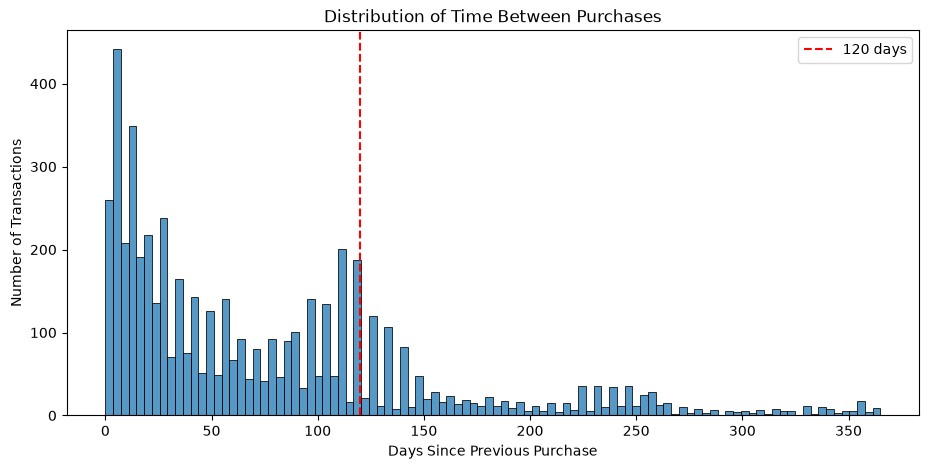

In [112]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=train_raw,
    x="days_since_previous_purchase",
    bins=100,
    binrange=(0, 365)
)

plt.axvline(120, color="red", linestyle="--", label="120 days")

plt.xlabel("Days Since Previous Purchase")
plt.ylabel("Number of Transactions")
plt.title("Distribution of Time Between Purchases")
plt.legend()
plt.show()

In [113]:
intervals = train_raw["days_since_previous_purchase"].dropna()

print("Around 4 months (105–135 days):",
      intervals.between(105, 135).sum())

print("Around 8 months (225–255 days):",
      intervals.between(225, 255).sum())

print("Total known intervals:", len(intervals))

Around 4 months (105–135 days): 820
Around 8 months (225–255 days): 175
Total known intervals: 5673


The temporal analysis revealed recurring transaction-volume peaks in March, July and November. Additionally, 14.5% of known interpurchase intervals fall between 105 and 135 days, while 3.1% fall between 225 and 255 days. These observations suggest possible periodicity in purchasing behavior, although further investigation would be necessary to establish whether a recurring four-month cycle exists.

In [114]:
train_raw.columns.tolist()

['Total a Pagar',
 'Total Bruto',
 'Total Liquido',
 'Total Imp_',
 'Total Portes',
 'Total Desc_ Global',
 'Total Desc_ Linha',
 'Custo',
 'N_ Detalhes',
 'invoice_count_current_purchase',
 'repeat_purchase_90d',
 'spend_next_90d',
 'days_since_previous_purchase',
 'customer_tenure_days',
 'prior_purchase_count',
 'prior_total_spend',
 'prior_mean_purchase_value',
 'prior_std_purchase_value',
 'prior_min_purchase_value',
 'prior_max_purchase_value',
 'prior_mean_gap_days',
 'prior_std_gap_days',
 'purchase_count_30d',
 'spend_30d',
 'purchase_count_90d',
 'spend_90d',
 'purchase_count_180d',
 'spend_180d',
 'purchase_count_365d',
 'spend_365d',
 'customer_id',
 'payment_type',
 'salesperson',
 'commercial_zone',
 'transport_method',
 'warehouse',
 'document_series',
 'purchase_date',
 'ID',
 'random_noise']

In [115]:
train_raw[
    ["prior_mean_gap_days", "prior_std_gap_days"]
].describe()

,prior_mean_gap_days,prior_std_gap_days
count,5226.000000,5056.000000
mean,95.876660,74.135443
std,122.589306,101.819540
min,-4.000000,0.000000
25%,42.596591,32.736068
50%,68.444444,50.635354
75%,113.831579,78.626119
max,3199.000000,2212.537118


In [116]:
train_raw[
    ["prior_mean_gap_days", "prior_std_gap_days"]
].isna().sum()

prior_mean_gap_days    1308
prior_std_gap_days     1478
dtype: int64

In [117]:
train_raw.loc[
    train_raw["prior_mean_gap_days"] < 0,
    ["customer_id", "purchase_date", "prior_purchase_count",
     "prior_mean_gap_days", "prior_std_gap_days"]
]

,customer_id,purchase_date,prior_purchase_count,prior_mean_gap_days,prior_std_gap_days
354,137415,2024-02-18,21.0,-4.0,61.441350
556,441324,2016-01-24,2.0,-4.0,NaN
823,554016,2019-04-14,2.0,-4.0,NaN
1305,438652,2023-04-11,45.0,-4.0,37.720872
1775,274962,2020-03-28,17.0,-4.0,45.272094
2418,441324,2024-02-11,40.0,-4.0,83.848355
3200,274962,2016-03-20,2.0,-4.0,NaN
3228,543949,2023-04-01,16.0,-4.0,61.808999
3289,944110,2022-10-22,13.0,-4.0,51.709196
4184,103940,2019-12-22,136.0,-4.0,6.652082


In [118]:
train_raw.groupby("prior_purchase_count").agg(
    observations=("customer_id", "size"),
    missing_mean_gap=("prior_mean_gap_days", lambda x: x.isna().sum()),
    missing_std_gap=("prior_std_gap_days", lambda x: x.isna().sum())
).head(10)

,observations,missing_mean_gap,missing_std_gap
prior_purchase_count,,,
0.0,603,603,603
1.0,445,445,445
2.0,365,21,365
3.0,319,17,0
4.0,270,7,0
5.0,248,8,0
6.0,222,7,0
7.0,203,11,0
8.0,192,7,0


0 previous purchases: No historical intervals exist.



1 previous purchase: Still no interval between previous purchases.



2 previous purchases: One interval exists, but there's insufficient information for a sample standard deviation.



3+ previous purchases: Both statistics can generally be calculated.

In [119]:
unexpected_missing = train_raw[
    (train_raw["prior_purchase_count"] >= 2)
    & (train_raw["prior_mean_gap_days"].isna())
]

print("Unexpected missing mean gaps:", len(unexpected_missing))

display(
    unexpected_missing[
        ["customer_id", "prior_purchase_count",
         "prior_mean_gap_days", "prior_std_gap_days"]
    ].head(15)
)

Unexpected missing mean gaps: 195


,customer_id,prior_purchase_count,prior_mean_gap_days,prior_std_gap_days
12,122356,23.0,NaN,66.789924
21,239651,49.0,NaN,43.438368
24,227020,6.0,NaN,27.770488
65,371073,3.0,NaN,33.234019
76,597661,48.0,NaN,40.136850
134,733919,2.0,NaN,NaN
167,427118,8.0,NaN,42.292631
220,868700,6.0,NaN,172.289582
287,851871,2.0,NaN,NaN
404,971102,2.0,NaN,NaN


In [121]:
regularity_data = train_raw[
    (train_raw["prior_mean_gap_days"] > 0)
    & (train_raw["prior_std_gap_days"].notna())
].copy()

regularity_data["gap_cv"] = (
    regularity_data["prior_std_gap_days"]
    / regularity_data["prior_mean_gap_days"]
)

regularity_data["gap_cv"].describe()

count    4870.000000
mean        0.841122
std         0.323117
min         0.000000
25%         0.635676
50%         0.828403
75%         1.014949
max         3.965251
Name: gap_cv, dtype: float64

In [123]:
regularity_data["regularity_group"] = pd.qcut(
    regularity_data["gap_cv"],
    q=5,
    duplicates="drop"
)

regularity_analysis = (
    regularity_data.groupby("regularity_group", observed=True)["repeat_purchase_90d"]
    .agg(["count", "mean"])
)

regularity_analysis

,count,mean
regularity_group,,
"(-0.001, 0.589]",974,0.441478
"(0.589, 0.752]",974,0.536961
"(0.752, 0.904]",974,0.637577
"(0.904, 1.071]",974,0.760780
"(1.071, 3.965]",974,0.683778


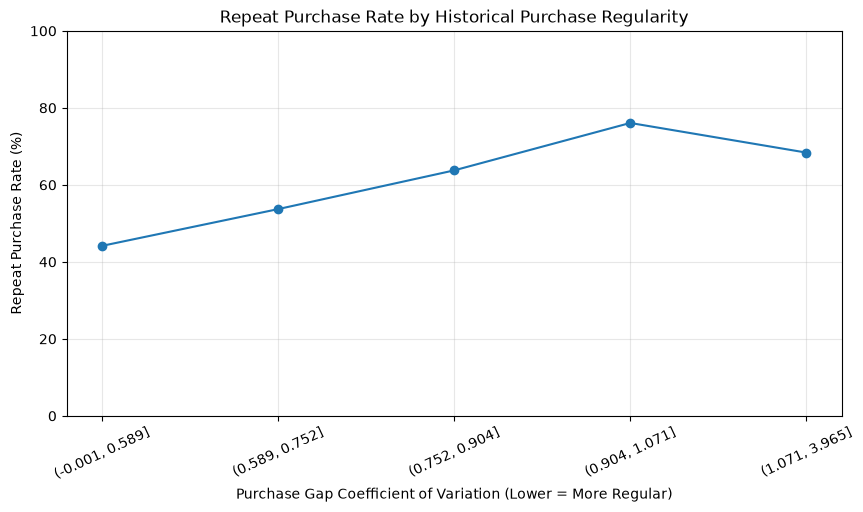

In [124]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(len(regularity_analysis)),
    regularity_analysis["mean"] * 100,
    marker="o"
)

plt.xticks(
    range(len(regularity_analysis)),
    [str(group) for group in regularity_analysis.index],
    rotation=25
)

plt.xlabel("Purchase Gap Coefficient of Variation (Lower = More Regular)")
plt.ylabel("Repeat Purchase Rate (%)")
plt.title("Repeat Purchase Rate by Historical Purchase Regularity")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.show()

Historical purchase-gap variability exhibits a non-monotonic association with repeat purchasing. The repeat purchase rate increases from 44.1% in the lowest CV group to 76.1% in the fourth group, before decreasing to 68.4% in the highest group.

In [125]:
regularity_profile = (
    regularity_data.groupby("regularity_group", observed=True)
    .agg(
        observations=("customer_id", "size"),
        unique_customers=("customer_id", "nunique"),
        median_mean_gap=("prior_mean_gap_days", "median"),
        median_previous_purchases=("prior_purchase_count", "median"),
        median_recency=("days_since_previous_purchase", "median"),
        repeat_rate=("repeat_purchase_90d", "mean")
    )
)

regularity_profile

,observations,unique_customers,median_mean_gap,median_previous_purchases,median_recency,repeat_rate
regularity_group,,,,,,
"(-0.001, 0.589]",974,183,101.791667,9.0,98.0,0.441478
"(0.589, 0.752]",974,171,77.763393,16.0,75.0,0.536961
"(0.752, 0.904]",974,170,60.322078,21.0,49.0,0.637577
"(0.904, 1.071]",974,132,48.344985,26.0,28.0,0.760780
"(1.071, 3.965]",974,141,59.849691,18.0,33.0,0.683778


- Customer A purchases consistently every 120 days.
- Customer B purchases at irregular intervals averaging 30 days.
Customer A is more regular, but Customer B may have a greater chance of purchasing within the next 90 days simply because they generally purchase more frequently.

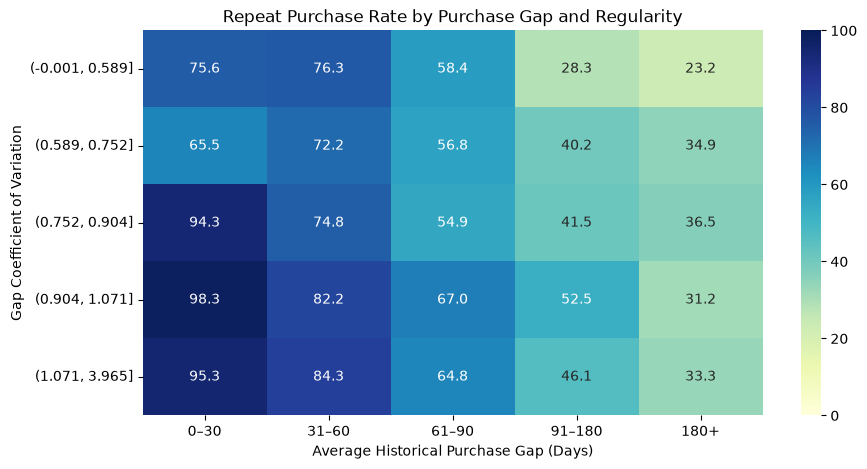

mean_gap_group,0–30,31–60,61–90,91–180,180+
regularity_group,,,,,
"(-0.001, 0.589]",41,190,161,487,95
"(0.589, 0.752]",29,205,366,331,43
"(0.752, 0.904]",123,357,266,176,52
"(0.904, 1.071]",298,270,182,160,64
"(1.071, 3.965]",170,319,165,167,153


In [126]:
regularity_data["mean_gap_group"] = pd.cut(
    regularity_data["prior_mean_gap_days"],
    bins=[0, 30, 60, 90, 180, float("inf")],
    labels=["0–30", "31–60", "61–90", "91–180", "180+"]
)

regularity_heatmap = regularity_data.pivot_table(
    index="regularity_group",
    columns="mean_gap_group",
    values="repeat_purchase_90d",
    aggfunc="mean",
    observed=True
)

regularity_counts = regularity_data.pivot_table(
    index="regularity_group",
    columns="mean_gap_group",
    values="repeat_purchase_90d",
    aggfunc="count",
    observed=True
)

plt.figure(figsize=(10, 5))

sns.heatmap(
    regularity_heatmap * 100,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)

plt.xlabel("Average Historical Purchase Gap (Days)")
plt.ylabel("Gap Coefficient of Variation")
plt.title("Repeat Purchase Rate by Purchase Gap and Regularity")
plt.show()

display(regularity_counts)

We started with the hypothesis:
Customers with more regular purchasing intervals are more likely to return.
Our EDA challenged that hypothesis.
We discovered that:
1. More irregular customers initially appeared more likely to return.
2. Those customers also tended to purchase more frequently and more recently.
3. When comparing customers with similar average purchase gaps, some differences associated with regularity remained.
4. The strongest visible pattern in the heatmap is that shorter average purchase gaps are associated with higher repeat purchase rates, across all five CV groups.
This is a good example of why exploring relationships between multiple features matters. A simple graph can be misleading when other characteristics differ between groups.
My conclusion: prior_mean_gap_days looks particularly promising as a predictive feature. gap_cv may also contain useful information, but its additional value remains unproven.